In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import json

In [4]:
df = pd.read_csv('./cancer_data.csv')

In [5]:
print(df.shape)
print(df.columns)

(569, 33)
Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='str')


In [6]:
# Remove unnecessary last column
cleaned_df = df.drop(['Unnamed: 32'], axis = 1)

In [7]:
columnNames = list(cleaned_df.columns)
for col in columnNames:
    print(f"Data type of {col}: ", type(df[col].unique()))

Data type of id:  <class 'numpy.ndarray'>
Data type of diagnosis:  <class 'pandas.arrays.StringArray'>
Data type of radius_mean:  <class 'numpy.ndarray'>
Data type of texture_mean:  <class 'numpy.ndarray'>
Data type of perimeter_mean:  <class 'numpy.ndarray'>
Data type of area_mean:  <class 'numpy.ndarray'>
Data type of smoothness_mean:  <class 'numpy.ndarray'>
Data type of compactness_mean:  <class 'numpy.ndarray'>
Data type of concavity_mean:  <class 'numpy.ndarray'>
Data type of concave points_mean:  <class 'numpy.ndarray'>
Data type of symmetry_mean:  <class 'numpy.ndarray'>
Data type of fractal_dimension_mean:  <class 'numpy.ndarray'>
Data type of radius_se:  <class 'numpy.ndarray'>
Data type of texture_se:  <class 'numpy.ndarray'>
Data type of perimeter_se:  <class 'numpy.ndarray'>
Data type of area_se:  <class 'numpy.ndarray'>
Data type of smoothness_se:  <class 'numpy.ndarray'>
Data type of compactness_se:  <class 'numpy.ndarray'>
Data type of concavity_se:  <class 'numpy.ndarr

## Preprocessing

In [8]:
# See there are no blank values present
cleaned_df[cleaned_df.apply(lambda x: x.count(), axis=1) != 32].shape

(0, 32)

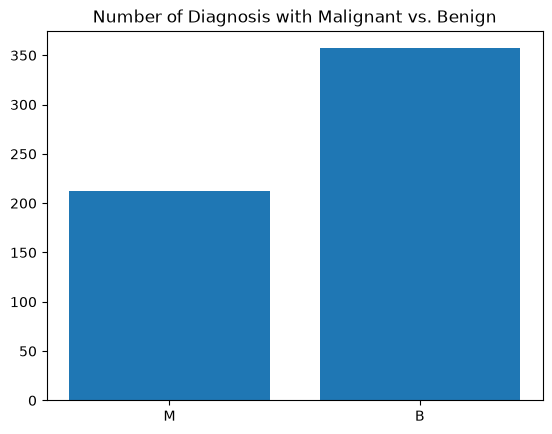

In [9]:
malignant = cleaned_df[cleaned_df['diagnosis'] == "M"]
benign = cleaned_df[cleaned_df['diagnosis'] == "B"]

diagnosis = [len(malignant), len(benign)]

plt.bar(['M', 'B'], diagnosis)
plt.title("Number of Diagnosis with Malignant vs. Benign")
plt.show()

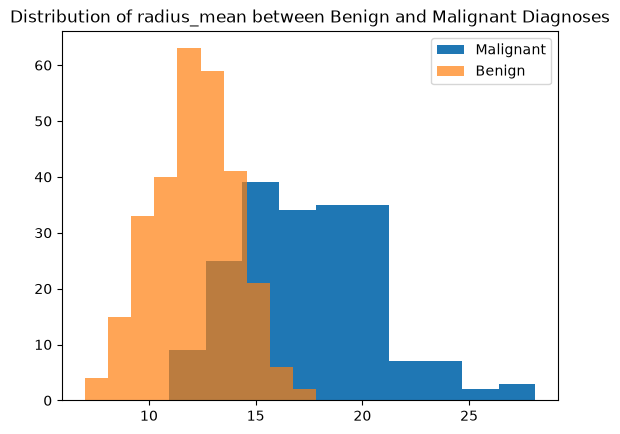

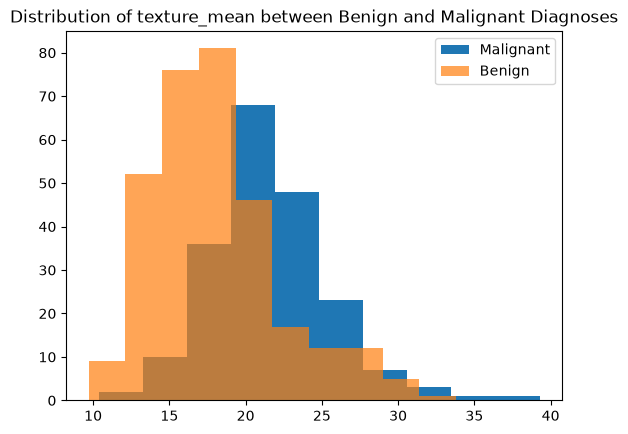

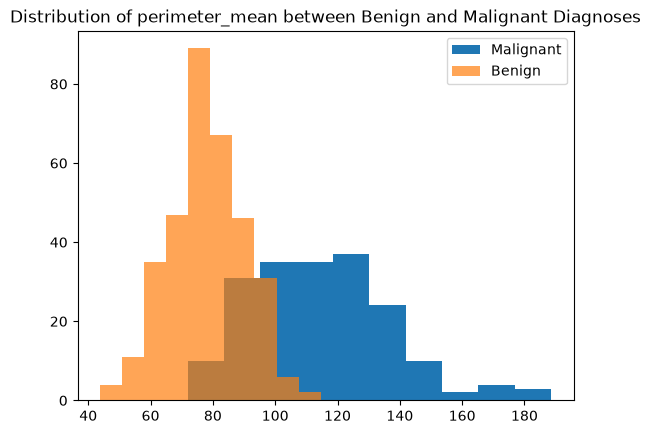

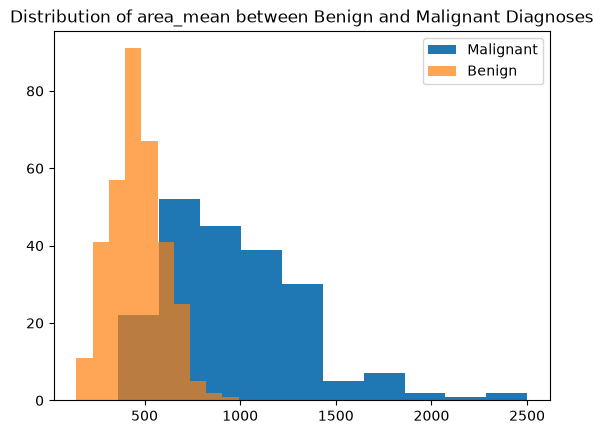

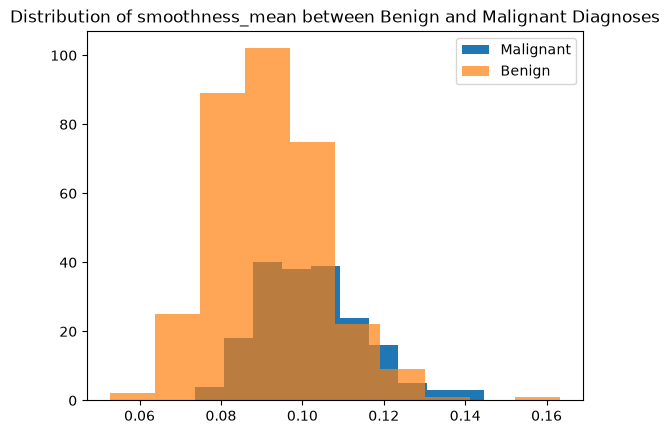

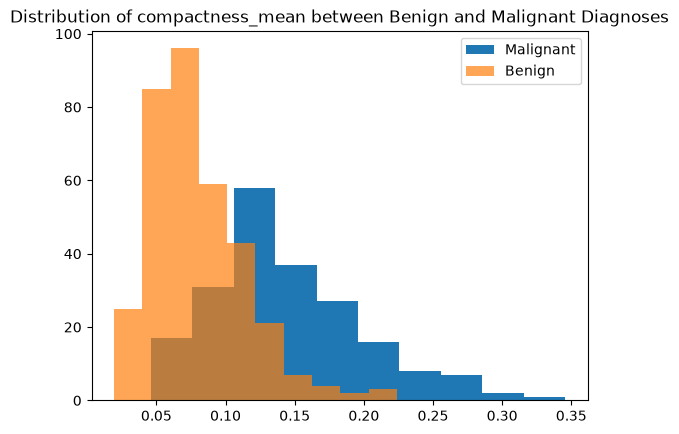

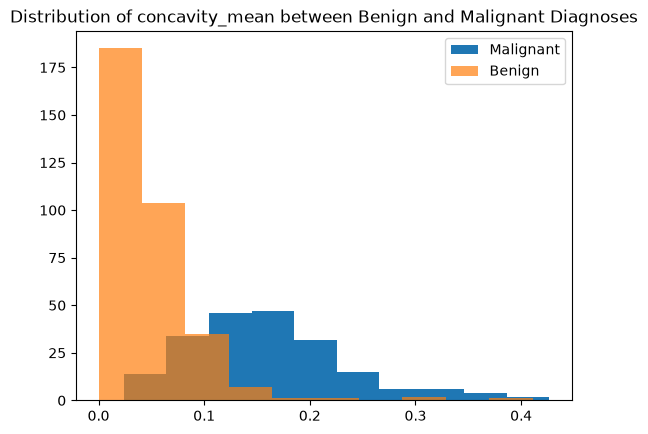

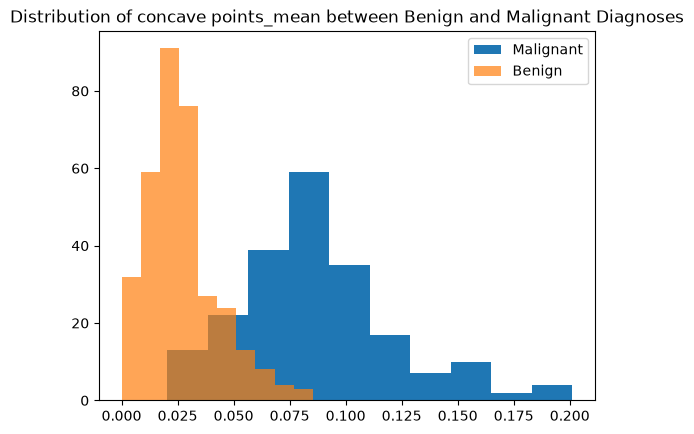

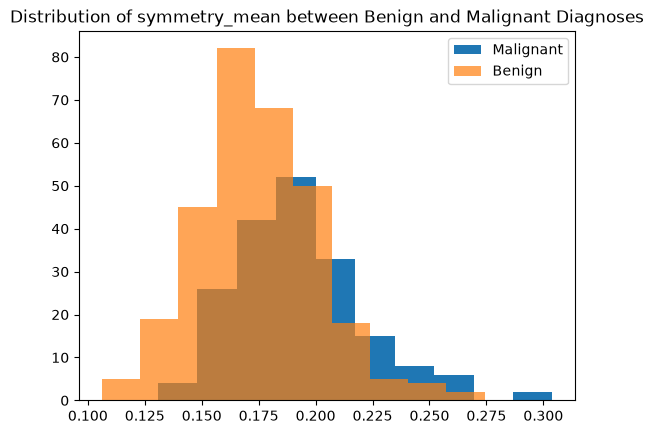

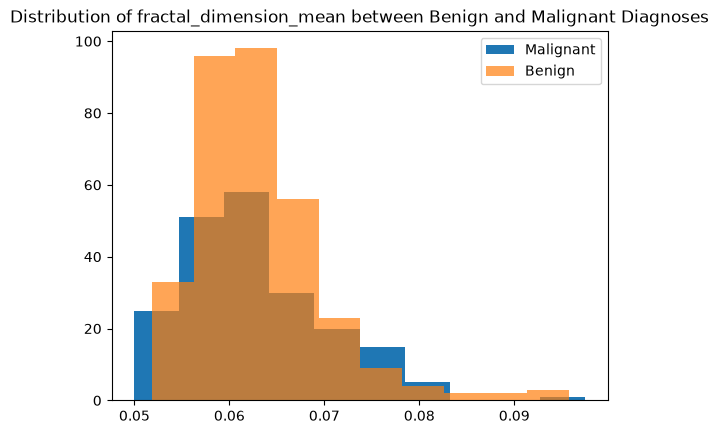

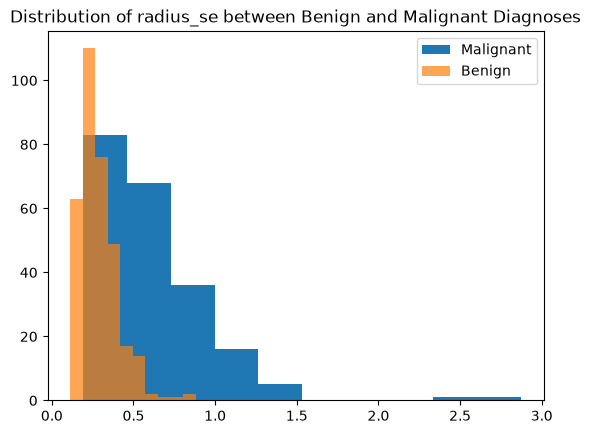

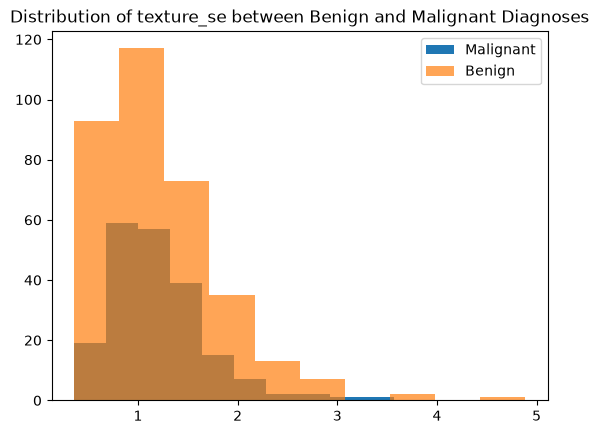

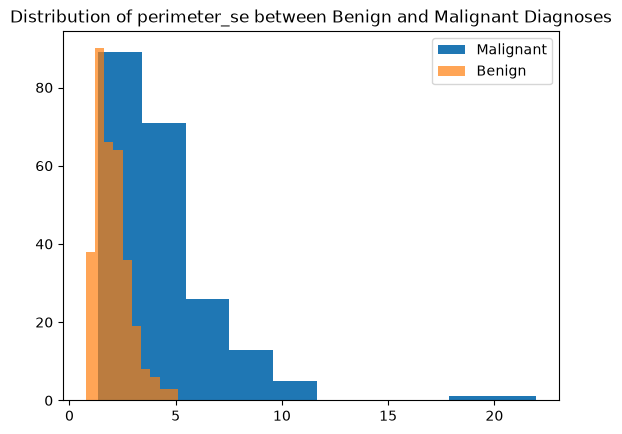

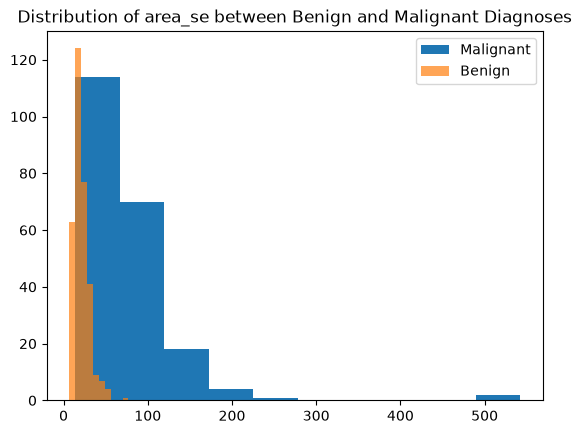

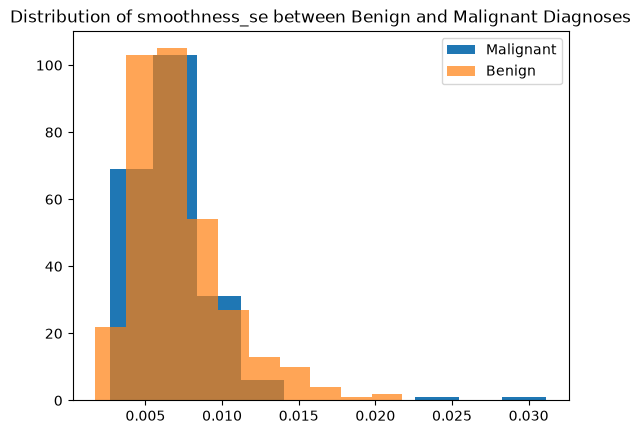

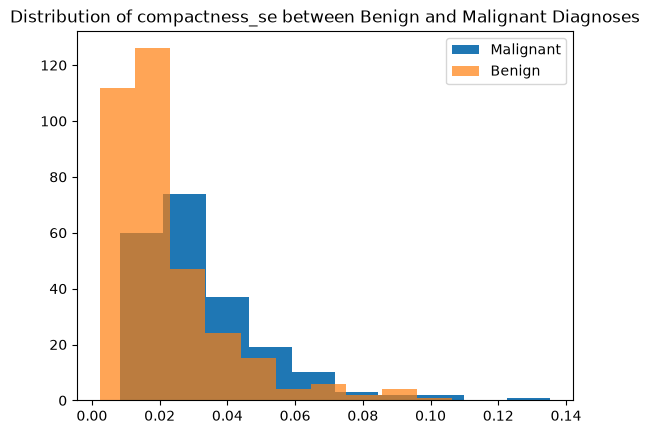

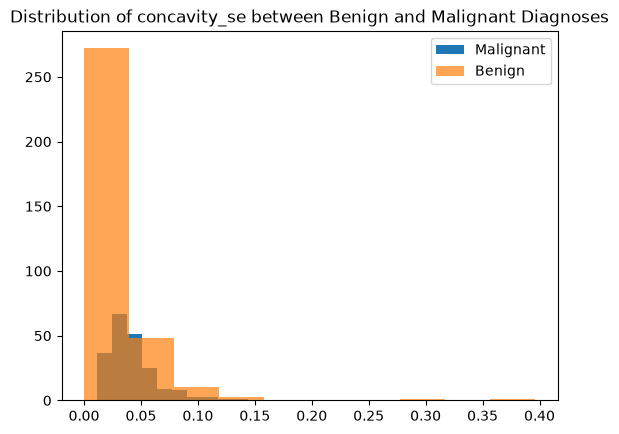

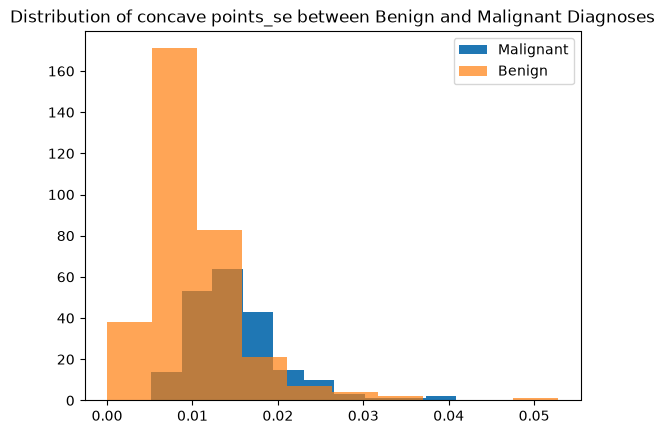

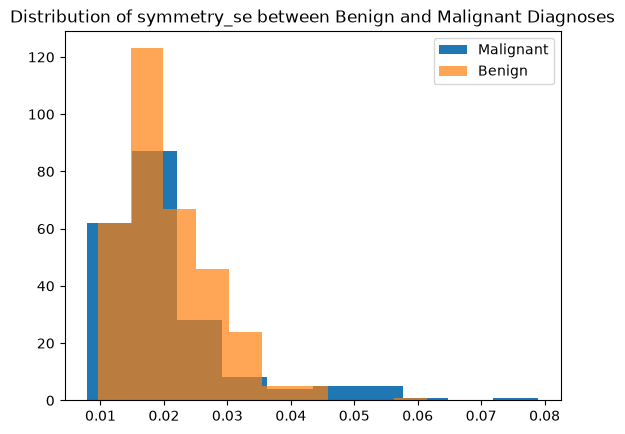

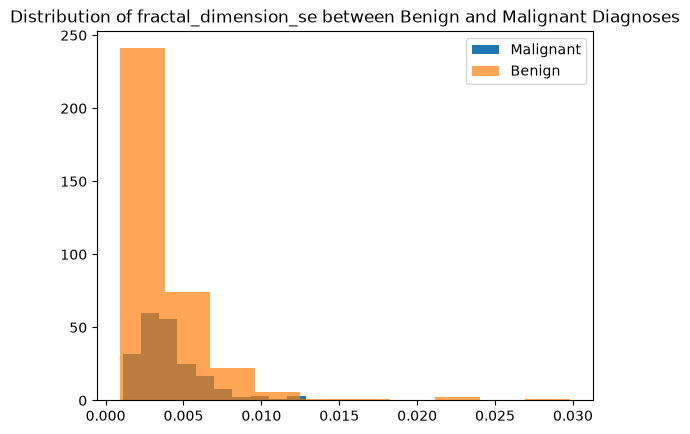

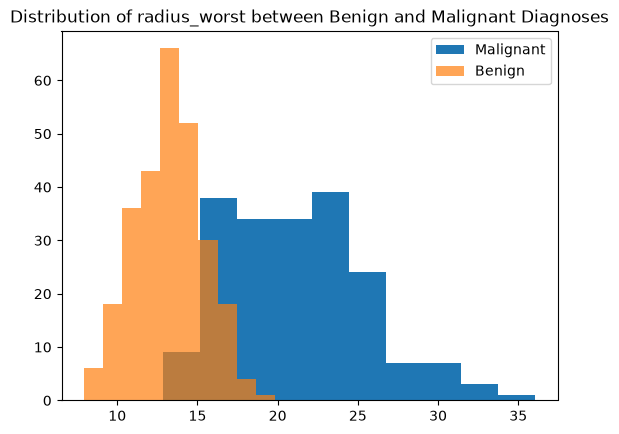

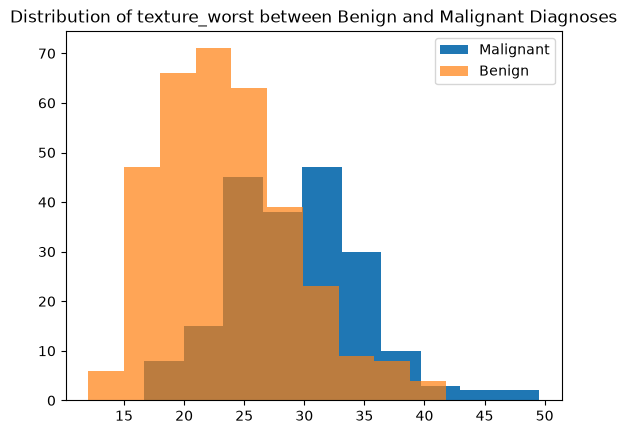

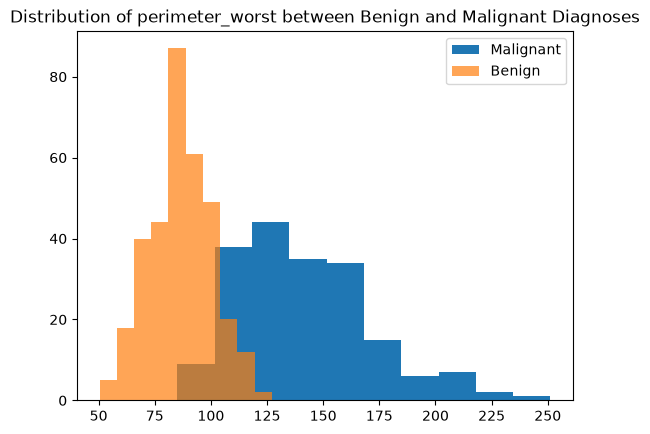

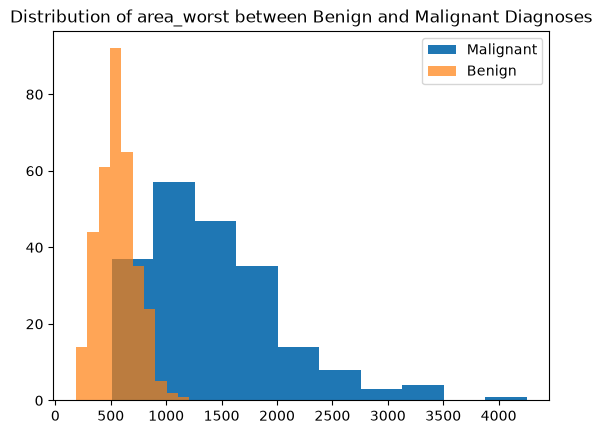

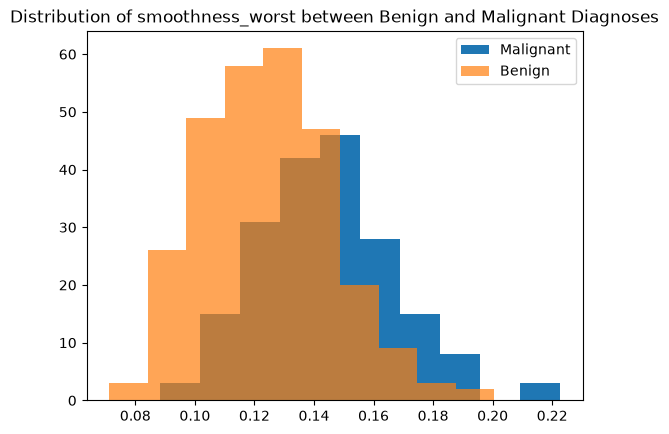

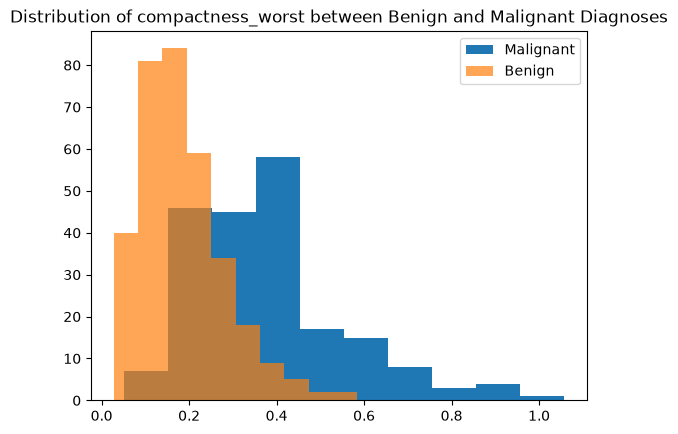

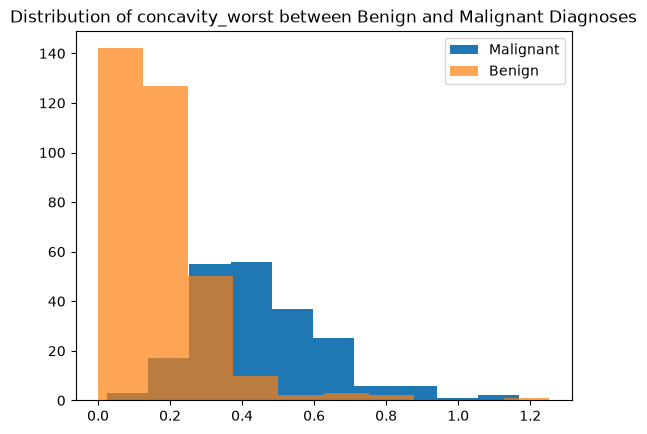

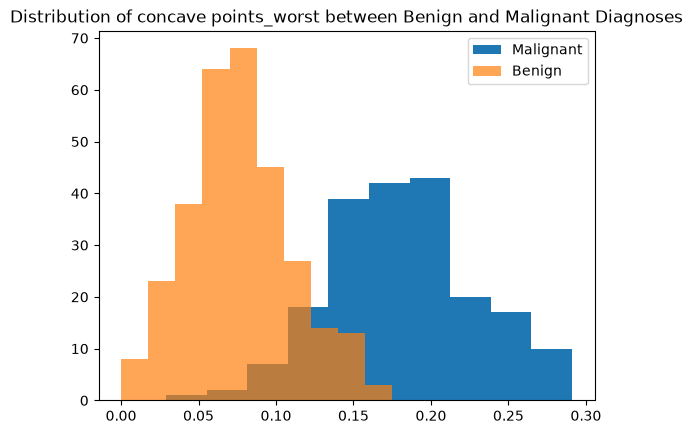

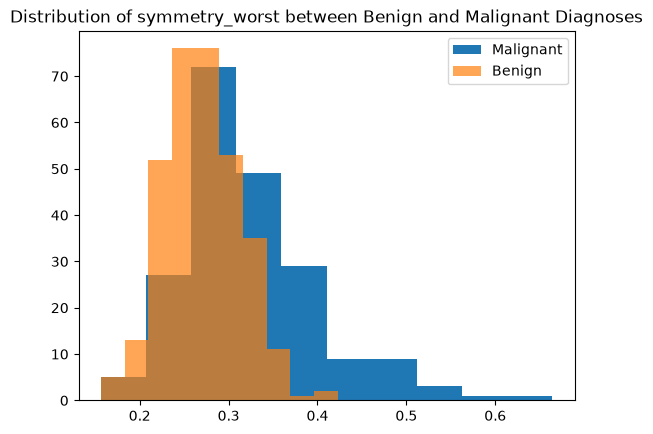

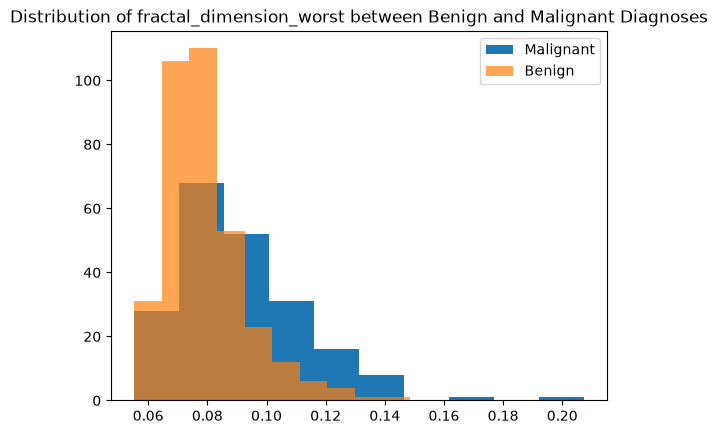

In [16]:
m_data = {}
b_data = {}

for feature in cleaned_df.columns[2:]:
    m_data[feature] = {}
    b_data[feature] = {}

    m_feature = cleaned_df[cleaned_df['diagnosis'] == 'M'][feature]
    b_feature = cleaned_df[cleaned_df['diagnosis'] == 'B'][feature]
    
    m_counts, m_bins, m_bars = plt.hist(m_feature.unique(), label = "Malignant")
    b_counts, b_bins, b_bars = plt.hist(b_feature.unique(), label = "Benign", alpha = 0.7)  

    for i in range(np.size(m_counts)):
        value_range = f"{m_bins[i]}-{m_bins[i+1]}"
        m_data[feature][value_range] = m_counts[i]
    
    for i in range(np.size(b_counts)):
        start = b_bins[i]
        value_range = f"{b_bins[i]}-{b_bins[i+1]}"
        b_data[feature][value_range] = b_counts[i]

    plt.title(f"Distribution of {feature} between Benign and Malignant Diagnoses")
    plt.legend()
    plt.show()

In [20]:
data_file = Path('feature_ranges.json')
data_file.write_text(json.dumps({'malignant': m_data, 'benign': b_data}, indent=4), encoding='utf-8')

29182